#### Amortized Optimization (FB Research)

The goal is to show how to use amortized optimization to learn to solve problems over sphered of the form
- $y^*(x) \in \underset{{y \in S^2}}{\operatorname{argmin}} f(y;x)$

where
$S^2$ is the surface of the unit 2-sphere embedded in ${R}^3$ as $S^
2 := \{y \in {R}^3 | \lVert y \lVert_2=1\}$ and
$x$ is some parameterization of the function $f : S^2 \times {X} \rightarrow {R} $.

The objective is to find the extreme values of a function defined on Earth or other spaces that can be approximated with a sphere.


##### Amortization Objective

The objective function needs to be transformed first from a constraint optimization into an uncostrained optimization using a projection
- $y^*(x) \in \underset{{y \in \mathbb{R}^3}}{\operatorname{argmin}} f(\pi_{S^
2}(y);x)$

where $\pi_{S^
2}: \mathbb{R}^3 \rightarrow S^
2$ is is the Euclidean projection onto
Celestial space
$\pi_{s^
2}(x):
= \underset{{y \in S^
2}}{\operatorname{argmin}} \lVert y-x\lVert_2
=
x/\lVert x \rVert_2$

#### c-convex functions on the sphere

$f(y;x)=min_\gamma \{\frac{1}{2} d(x,z_i) + \alpha_i\}^m_{i=1}$

where $m$ components define the context $x=\{z_i\} \cup \{\alpha_i\}$ with $z_i \in
S^
2$ and $\alpha_i \in \mathbb{R}$,

$d(x; y) :
= \arccos(x^T y)$ is the Riemannian distance on the sphere in the ambient
Euclidean space.  
Riemannian optimal transport replaces the Euclidean functions with so called c-convex or c-concave functions, and the Euclidean translation by exponential map.

$min_\gamma (a_1,...,a_m)=-\gamma log \sum_{i=1}^{m} \exp(-a_i/\gamma)$ is a soft
minimization operator
The context distribution $p(x)$ is sampled with $z_i \sim {U}(S^
2)$, i.e.
uniformly from the sphere and $\alpha_i \sim {N}(0; \beta)$ with variance $\beta
\in \mathbb{R}_+$

#### Implementation

Amortized Optimization on Spherical Surfaces:
- Theory focuses on parameterizing a constrained optimization objective onto the unit 2-sphere ($S^2$) to locate extreme values using Euclidean projection mappings.

- Target Landscapes using parameterized, highly non-convex $c$-convex functions (Riemannian distance matrices with uniform/normal variance components).

- Optimization Model, an AmortizedModel (Multi-Layer Perceptron) that predicts the sphere coordinates optimizing the given function's landscape from parameter contexts directly.

Visualizations
- Mollweide projection maps show optimization trajectories over the sphere contour lines for 8 functions. Grid of 3D spherical terrain surfaces using a consistent globally-normalized color scale. A 3D animated trace of the optimization trajectory navigating across the spherical surface.


In [6]:
def celest_to_euc(ra, dec):
    # Since we might pass numpy arrays or torch tensors, we can keep them compatible
    if torch.is_tensor(ra):
        x = torch.cos(dec)*torch.cos(ra)
        y = torch.cos(dec)*torch.sin(ra)
        z = torch.sin(dec)
    else:
        x = np.cos(dec)*np.cos(ra)
        y = np.cos(dec)*np.sin(ra)
        z = np.sin(dec)
    return x, y, z

def euc_to_celest(x, y, z):
    if torch.is_tensor(x):
        sindec = z
        cosdec = torch.sqrt(x**2 + y**2)
        sinra = y/cosdec
        cosra = x/cosdec
        ra = torch.atan2(sinra, cosra)
        dec = torch.atan2(sindec, cosdec)
    else:
        sindec = z
        cosdec = np.sqrt(x**2 + y**2)
        sinra = y/cosdec
        cosra = x/cosdec
        ra = np.arctan2(sinra, cosra)
        dec = np.arctan2(sindec, cosdec)
    return ra, dec

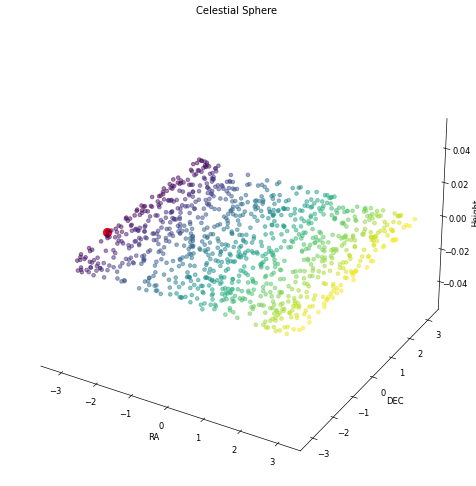

In [7]:
# generate random points on the sphere
num_points = 1000
ra_dec = np.random.rand(num_points, 2)*2*np.pi - np.pi
x, y, z = celest_to_euc(ra_dec[:, 0], ra_dec[:, 1])

# 3D plot of the celestial sphere in celestial coordinates
fig_cel = plt.figure(figsize=(10, 10), dpi=60)
ax_cel = fig_cel.add_subplot(111, projection='3d')
ax_cel.scatter(ra_dec[:, 0], ra_dec[:, 1], c = ra_dec[:,0], s=20, alpha=0.5)

min_point_idx = np.argmin(ra_dec[:, 0])
ax_cel.scatter(ra_dec[min_point_idx, 0], ra_dec[min_point_idx, 1], c='r', s=100)

ax_cel.set_xlabel('RA')
ax_cel.set_ylabel('DEC')
ax_cel.set_zlabel('Height')
ax_cel.set_title('Celestial Sphere')

ax_cel.yaxis.set_pane_color('white')
ax_cel.xaxis.set_pane_color('white')
ax_cel.zaxis.set_pane_color('white')
ax_cel.grid(False)
plt.show()

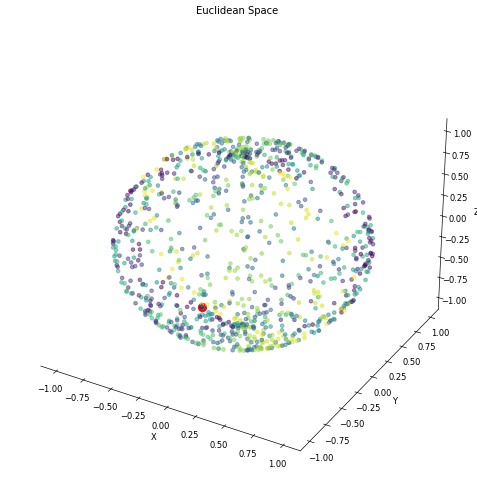

In [8]:
# 3D plot of the cartesian sphere
fig_cart = plt.figure(figsize=(10, 10), dpi=60)
ax_cart = fig_cart.add_subplot(111, projection='3d')
ax_cart.scatter(x, y, z, c = ra_dec[:,0], s=20, alpha=0.5,)

min_point_idx = np.argmin(ra_dec[:, 0])
ax_cart.scatter(x[min_point_idx], y[min_point_idx], z[min_point_idx], c='r', s=100)

ax_cart.scatter(x[min_point_idx], y[min_point_idx], z[min_point_idx])

ax_cart.set_xlabel('X')
ax_cart.set_ylabel('Y')
ax_cart.set_zlabel('Z')
ax_cart.set_title('Euclidean Space')

ax_cart.yaxis.set_pane_color('white')
ax_cart.xaxis.set_pane_color('white')
ax_cart.zaxis.set_pane_color('white')
ax_cart.grid(False)
plt.show()

In [9]:
# Riemannian distance between two points on the sphere
# use vectorized operations
def sphere_dist(x, y):
    if x.ndim == 1: x = x.unsqueeze(0)
    if y.ndim == 1: y = y.unsqueeze(0)
    assert x.ndim == 2 and y.ndim == 2, 'x and y must be 2D tensors'
    inner = (x*y).sum(-1)
    # Clamping is recommended to prevent NaNs near -1.0 and 1.0 due to numerical precision issues
    inner = torch.clamp(inner, -1.0 + 1e-7, 1.0 - 1e-7)
    return torch.acos(inner)

In [10]:
# define c-convex function
class c_convex(nn.Module):
    def __init__(self, n_components=4, gamma=0.5, seed=None ):
        super().__init__()
        self.n_components = n_components
        self.gamma = gamma
        self.seed = seed

        if seed is not None:
            torch.manual_seed(seed)

        self.ys = torch.randn(n_components, 3)
        self.ys = self.ys / torch.norm(self.ys, 2, dim=-1, keepdim=True)
        self.alphas = .7 * torch.rand(n_components)
        self.params = torch.cat((self.ys.view(-1), self.alphas.view(-1)))

    def forward(self, xyz):
        cs = []
        for y, alpha in zip(self.ys, self.alphas):
            ci = 0.5 * sphere_dist(xyz, y)**2 + alpha
            cs.append(ci)
        cs = torch.stack(cs)
        if self.gamma == None or self.gamma ==0.:
            z = cs.min(dim=0).values
        else:
            z = -torch.logsumexp(-self.gamma*(-cs/self.gamma), dim=0)
            #z = -self.gamma*(-cs/self.gamma).logsumexp(dim=0)
        return z

In [11]:
# sample a random c-convex function
seeds = [8, 9, 2, 7, 20, 16, 31, 4]
fs = [c_convex(seed=i) for i in seeds]
n_params = len(fs[0].params)

In [12]:
# define base amortized model
class AmortizedModel(nn.Module):
    def __init__(self, n_params, hidden_dim):
        super().__init__()
        self.fc1 = nn.Linear(n_params, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        self.fc3 = nn.Linear(hidden_dim, 3)
        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

        self.base = nn.Sequential(self.fc1, self.relu, self.fc2, self.relu, self.fc3, self.sigmoid)

    def forward(self, x):
        squeeze = x.ndim == 1
        if squeeze: x = x.unsqueeze(0)
        assert x.ndim ==2
        z = self.base(x)
        z = z / torch.norm(z, dim=1, keepdim=True)
        if squeeze: z = z.squeeze(0)
        return z

In [13]:
# define model and optimizer
n_hidden = 128
torch.manual_seed(0)
model = AmortizedModel(n_params, n_hidden)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)

In [ ]:
# train the model
from tqdm import tqdm
xs = []
num_iterations = 100
pbar = tqdm(range(num_iterations), desc='Training Progress')

for idx in pbar:
    losses = []
    xis = []
    for f_ in fs:
        pred_opt = model(f_.params)
        xis.append(pred_opt)
        losses.append(f_(pred_opt))
    with torch.no_grad():
        xis = torch.stack(xis)
        xs.append(xis)
    loss = sum(losses)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

xs = torch.stack(xs, dim=1)

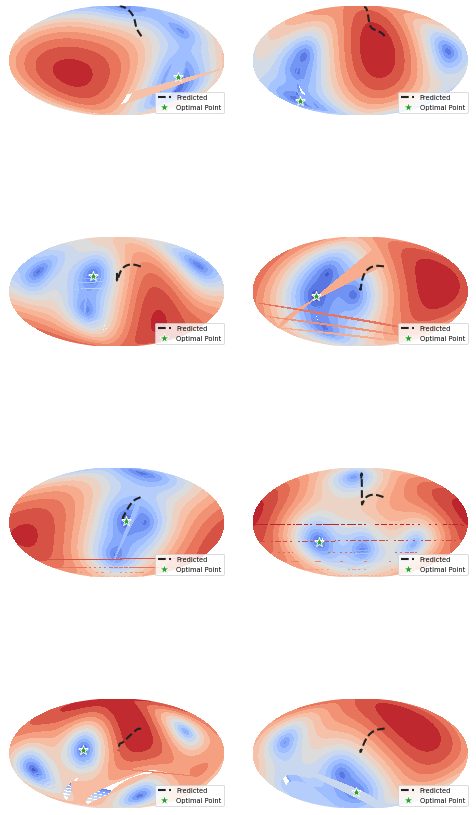

In [22]:
pad = .1
n_sample = 100
ra = np.linspace(-np.pi+pad, np.pi-pad, n_sample)
dec= np.linspace(-np.pi/2+pad, np.pi/2-pad, n_sample)

ra_grid, dec_grid = np.meshgrid(ra,dec)
ra_grid_flat = ra_grid.ravel()
dec_grid_flat = dec_grid.ravel()
x_grid, y_grid, z_grid = celest_to_euc(ra_grid_flat, dec_grid_flat)

p_grid = np.stack((x_grid, y_grid, z_grid), axis=-1)
p_grid_th = torch.from_numpy(p_grid).float()

nrow, ncol = len(fs) // 2, 2
fig, axes = plt.subplots(
    nrow, ncol, figsize=(10, 5 * nrow), dpi=60,
    subplot_kw={'projection': 'mollweide'},
    gridspec_kw={'wspace': 0.1, 'hspace': 0}
)

# Reshape axes if there is only one row
if nrow == 1:
    axes = np.array([axes])

for i, (f, xs_i) in enumerate(zip(fs, xs)):
    row = i // ncol
    col = i % ncol
    ax = axes[row, col]

    with torch.no_grad():
        f_grid = f(p_grid_th).numpy()
    best_i = f_grid.argmin()
    ra_opt, dec_opt = ra_grid_flat[best_i], dec_grid_flat[best_i]

    f_grid = f_grid.reshape(ra_grid.shape)
    n_levels = 15
    # Using 'coolwarm' for intuitive blue-to-red scale representation
    contour = ax.contourf(ra_grid, dec_grid, f_grid, n_levels, cmap='coolwarm')

    x, y, z = xs_i.split(1, dim=-1)
    ra, dec = euc_to_celest(x, y, z)
    line = ax.plot(ra, dec, color='#222222', lw=2.5, ls='--', label='Predicted')

    ax.scatter(ra_opt, dec_opt, marker='*', color='#2CA02C', edgecolor='white',
                        s=150, zorder=10, label='Optimal Point')

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, loc='lower right', fontsize=8)

    for s in ax.spines.values():
        s.set_visible(False)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

plt.show()

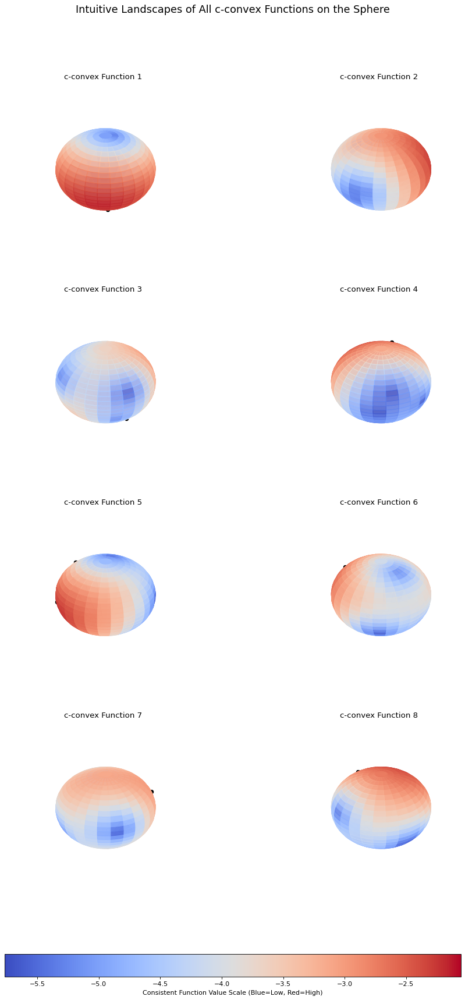

In [18]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
import torch

# Generate a grid on the sphere using spherical coordinates
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 100)

# Calculate Cartesian coordinates for the grid
x_grid = np.outer(np.cos(u), np.sin(v))
y_grid = np.outer(np.sin(u), np.sin(v))
z_grid = np.outer(np.ones(np.size(u)), np.cos(v))

# Flatten to pass through our model
points_3d = np.stack([x_grid.flatten(), y_grid.flatten(), z_grid.flatten()], axis=1)
points_tensor = torch.tensor(points_3d, dtype=torch.float32)

# First, evaluate all functions on the grid to find a consistent global scale
all_f_values = []
for f_visualize in fs:
    with torch.no_grad():
        val = f_visualize(points_tensor).numpy()
        all_f_values.append(val)

global_min = np.min(all_f_values)
global_max = np.max(all_f_values)

# Create 3D Subplots for all functions with a consistent colormap scale
nrow, ncol = (len(fs) + 1) // 2, 2
fig = plt.figure(figsize=(14, 6 * nrow), dpi=80)
colormap = plt.cm.coolwarm
norm = plt.Normalize(global_min, global_max)

for idx, (f_visualize, f_values) in enumerate(zip(fs, all_f_values)):
    ax = fig.add_subplot(nrow, ncol, idx + 1, projection='3d')
    f_grid = f_values.reshape(x_grid.shape)
    colors = colormap(norm(f_grid))

    # Plot the surface
    surface = ax.plot_surface(x_grid, y_grid, z_grid, facecolors=colors, shade=False, rstride=4, cstride=4, alpha=0.9)

    # Highlight anchor components (ys)
    with torch.no_grad():
        ys_np = f_visualize.ys.numpy()
    ax.scatter(ys_np[:, 0], ys_np[:, 1], ys_np[:, 2], color='black', edgecolor='white', s=60, depthshade=False)

    ax.set_title(f'c-convex Function {idx+1}')
    ax.set_axis_off()

# Add a single shared color bar at the bottom
fig.subplots_adjust(bottom=0.15)
cbar_ax = fig.add_axes([0.15, 0.08, 0.7, 0.02])
m = plt.cm.ScalarMappable(cmap=colormap, norm=norm)
m.set_array(np.array([global_min, global_max]))
fig.colorbar(m, cax=cbar_ax, orientation='horizontal', label='Consistent Function Value Scale (Blue=Low, Red=High)')

plt.suptitle('Intuitive Landscapes of All c-convex Functions on the Sphere', fontsize=16, y=0.95)
plt.show()

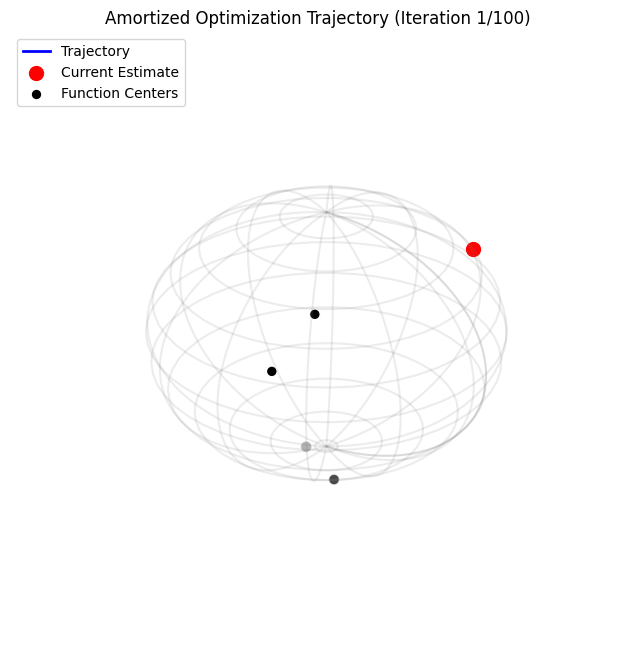

In [19]:
import matplotlib.animation as animation
from IPython.display import HTML

# Set up the grid for the background sphere
u_anim = np.linspace(0, 2 * np.pi, 50)
v_anim = np.linspace(0, np.pi, 50)
x_sphere = np.outer(np.cos(u_anim), np.sin(v_anim))
y_sphere = np.outer(np.sin(u_anim), np.sin(v_anim))
z_sphere = np.outer(np.ones(np.size(u_anim)), np.cos(v_anim))

# Let's animate the trajectory for the first function (fs[0])
# xs has shape (num_functions, num_iterations, 3)
traj_data = xs[0].detach().cpu().numpy()  # shape (100, 3)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

def update_plot(frame):
    ax.clear()
    # Plot semi-transparent wireframe sphere as background
    ax.plot_wireframe(x_sphere, y_sphere, z_sphere, color='gray', alpha=0.15, rstride=4, cstride=4)

    # Plot the full trajectory up to the current frame
    ax.plot(traj_data[:frame+1, 0], traj_data[:frame+1, 1], traj_data[:frame+1, 2],
            color='blue', lw=2, label='Trajectory')

    # Highlight the current position
    ax.scatter(traj_data[frame, 0], traj_data[frame, 1], traj_data[frame, 2],
               color='red', s=100, label='Current Estimate')

    # Highlight the anchor components (ys) of fs[0] as target centers
    with torch.no_grad():
        ys_np = fs[0].ys.numpy()
    ax.scatter(ys_np[:, 0], ys_np[:, 1], ys_np[:, 2], color='black', edgecolor='white', s=60, label='Function Centers')

    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-1.1, 1.1])
    ax.set_zlim([-1.1, 1.1])
    ax.set_title(f'Amortized Optimization Trajectory (Iteration {frame+1}/{len(traj_data)})')
    ax.legend(loc='upper left')
    ax.set_axis_off()

ani = animation.FuncAnimation(fig, update_plot, frames=len(traj_data), interval=100, repeat=False)
HTML(ani.to_jshtml())